# Method 10 (Pilot - Small Dataset): Frozen Backbone Book Context + Transformer Fine-Tuning

**Kiến trúc Method 10:**
1. **Backbone RT-DETRv2 (`backbone` + `frozen_ctx_proj`)**: **Đóng băng hoàn toàn** (`requires_grad = False`).
2. **Book Context Extraction**: Trích xuất feature maps đa tầng `(P3, P4, P5)` từ backbone đóng băng, gom trung bình theo từng cuốn sách (`book_of(img)`), lưu cache `float16` memmap trên `C:/doclaynet_cache/method10/`.
3. **Leave-One-Out & Zero-Gate Fusion**: Khi huấn luyện và suy luận, trừ chính trang hiện tại ra khỏi trung bình sách (Leave-One-Out) để chống leakage, đưa qua `ContextFusionAdapter` rồi cộng vào feature map chính với `fusion_gates` khởi tạo tại `0.0`.
4. **Transformer Fine-Tuning**: Fine-tune `encoder`, `decoder`, `context_adapter`, và `fusion_gates`.

Notebook này chạy **Pilot trên tập nhỏ** (25 sách Train, 8 sách Val, không rò rỉ sách) để kiểm chứng pipeline end-to-end, kiểm tra VRAM, tốc độ, gradient và COCO mAP.


In [1]:
import os
import sys
import json
import time
import random
import shutil
from pathlib import Path
from collections import defaultdict

import numpy as np
import torch
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

REPO_ROOT = Path(r"d:\Semester_261\DoAnChuyenNganh\DO-AN-261")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from methods.method10.common import (
    TRAIN_ANNO, VAL_ANNO,
    TRAIN_IMG_640, VAL_IMG_640,
    TRAIN_IMG_SRC, VAL_IMG_SRC,
    CACHE_DIR, WEIGHTS_DIR, REPORT_DIR,
    CATEGORIES, load_coco, book_of,
)
from methods.method10.models.rtdetr_method10 import BackboneContextRTDetrMethod10
from methods.method10.dataset import (
    precompute_backbone_book_context,
    Method10FastDataset,
    collate_fn_m10,
    evaluate_method10_coco_map,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"Total VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

c_free_gb = shutil.disk_usage("C:/").free / 1e9
print(f"C:/ free space: {c_free_gb:.2f} GB | CACHE_DIR: {CACHE_DIR}")

BATCH_SIZE = 4
GRAD_ACCUM = 2
EPOCHS = 3
LR = 5e-5
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 0  # Windows Jupyter safe (avoid multiprocessing deadlock)


Device: cuda
GPU: NVIDIA GeForce RTX 4070 Laptop GPU
Total VRAM: 8.59 GB
C:/ free space: 224.17 GB | CACHE_DIR: C:\doclaynet_cache\method10


In [2]:
def make_subset_coco(coco_dict: dict, selected_books: set) -> dict:
    imgs = [img for img in coco_dict["images"] if book_of(img) in selected_books]
    img_ids = {img["id"] for img in imgs}
    anns = [ann for ann in coco_dict["annotations"] if ann["image_id"] in img_ids]
    return {
        "images": imgs,
        "annotations": anns,
        "categories": coco_dict.get("categories", CATEGORIES),
    }

def pick_books_with_page_range(coco_dict: dict, n_books: int, min_pages: int = 4, max_pages: int = 12, seed: int = 42) -> set:
    by_book = defaultdict(list)
    for img in coco_dict["images"]:
        by_book[book_of(img)].append(img)
    eligible = sorted([b for b, ims in by_book.items() if min_pages <= len(ims) <= max_pages])
    rng = random.Random(seed)
    rng.shuffle(eligible)
    return set(eligible[:n_books])

print("Loading COCO annotations...")
full_train_coco = load_coco(TRAIN_ANNO)
full_val_coco = load_coco(VAL_ANNO)

pilot_train_books = pick_books_with_page_range(full_train_coco, n_books=25, min_pages=4, max_pages=12, seed=SEED)
pilot_val_books = pick_books_with_page_range(full_val_coco, n_books=8, min_pages=4, max_pages=15, seed=SEED + 1)
assert len(pilot_train_books & pilot_val_books) == 0, "Book leakage detected!"

pilot_train_coco = make_subset_coco(full_train_coco, pilot_train_books)
pilot_val_coco = make_subset_coco(full_val_coco, pilot_val_books)

print(f"Pilot Train: {len(pilot_train_books)} books, {len(pilot_train_coco['images'])} pages, {len(pilot_train_coco['annotations'])} boxes")
print(f"Pilot Val:   {len(pilot_val_books)} books, {len(pilot_val_coco['images'])} pages, {len(pilot_val_coco['annotations'])} boxes")


Loading COCO annotations...
Pilot Train: 25 books, 174 pages, 3577 boxes
Pilot Val:   8 books, 80 pages, 1113 boxes


In [3]:
model = BackboneContextRTDetrMethod10().to(device)

bb_trainable = sum(p.numel() for p in model.rtdetr.model.backbone.parameters() if p.requires_grad)
ctx_proj_trainable = sum(p.numel() for p in model.frozen_ctx_proj.parameters() if p.requires_grad)
enc_trainable = sum(p.numel() for p in model.rtdetr.model.encoder.parameters() if p.requires_grad)
dec_trainable = sum(p.numel() for p in model.rtdetr.model.decoder.parameters() if p.requires_grad)
adapter_trainable = sum(p.numel() for p in model.context_adapter.parameters() if p.requires_grad) + model.fusion_gates.numel()
total_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())

print(f"Frozen backbone trainable params:        {bb_trainable:,} (expected 0)")
print(f"Frozen ctx proj trainable params:        {ctx_proj_trainable:,} (expected 0)")
print(f"Trainable encoder params:                {enc_trainable:,}")
print(f"Trainable decoder params:                {dec_trainable:,}")
print(f"Trainable context_adapter + gates:       {adapter_trainable:,}")
print(f"Total trainable / Total params:          {total_trainable:,} / {total_params:,} ({100*total_trainable/total_params:.2f}%)")
assert bb_trainable == 0 and ctx_proj_trainable == 0


[Method10] Nạp pretrained RT-DETRv2 từ: docling-project/docling-layout-heron
[Method10] Đã đóng băng Backbone. Chỉ fine-tune Context Adapter + Projection + Transformer Encoder & Decoder.
Frozen backbone trainable params:        0 (expected 0)
Frozen ctx proj trainable params:        0 (expected 0)
Trainable encoder params:                11,031,808
Trainable decoder params:                6,931,006
Trainable context_adapter + gates:       1,967,619
Total trainable / Total params:          21,255,510 / 45,648,566 (46.56%)


In [4]:
train_mmap_path, train_book_idx = precompute_backbone_book_context(
    images_list=pilot_train_coco["images"],
    img_640_dir=TRAIN_IMG_640,
    img_raw_dir=TRAIN_IMG_SRC,
    model=model,
    split="train",
    batch_size=16,
    prefix="pilot_",
    device=device,
)

val_mmap_path, val_book_idx = precompute_backbone_book_context(
    images_list=pilot_val_coco["images"],
    img_640_dir=VAL_IMG_640,
    img_raw_dir=VAL_IMG_SRC,
    model=model,
    split="val",
    batch_size=16,
    prefix="pilot_",
    device=device,
)

train_ds = Method10FastDataset(pilot_train_coco, TRAIN_IMG_640, TRAIN_IMG_SRC, train_mmap_path, train_book_idx)
val_ds = Method10FastDataset(pilot_val_coco, VAL_IMG_640, VAL_IMG_SRC, val_mmap_path, val_book_idx)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"), collate_fn=collate_fn_m10,
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"), collate_fn=collate_fn_m10,
)
print(f"Train batches: {len(train_loader)} | Val batches: {len(val_loader)}")


[Method10 Cache] Loaded existing train book context cache: 25 books -> C:\doclaynet_cache\method10\pilot_book_ctx_train.npy
[Method10 Cache] Loaded existing val book context cache: 8 books -> C:\doclaynet_cache\method10\pilot_book_ctx_val.npy
Train batches: 44 | Val batches: 20


In [5]:
print("Evaluating Epoch 0 (Before Fine-Tuning)...")
ep0_metrics = evaluate_method10_coco_map(model, val_loader, pilot_val_coco, device, desc="Pilot Val Ep0")
print(f"Epoch 0 | mAP@[.50:.95]: {ep0_metrics['mAP']:.4f} | AP50: {ep0_metrics['AP50']:.4f} | AP75: {ep0_metrics['AP75']:.4f}")

trainable_params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW(trainable_params, lr=LR, weight_decay=WEIGHT_DECAY)
total_steps = max(1, (len(train_loader) // GRAD_ACCUM) * EPOCHS)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=total_steps, eta_min=LR * 0.1)
scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))


Evaluating Epoch 0 (Before Fine-Tuning)...
Epoch 0 | mAP@[.50:.95]: 0.7816 | AP50: 0.9229 | AP75: 0.8540


In [6]:
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

history = []
best_map = -1.0
best_ckpt = WEIGHTS_DIR / "best_pilot_method10.pt"

for epoch in range(1, EPOCHS + 1):
    t_ep = time.time()
    model.train()
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()

    optimizer.zero_grad(set_to_none=True)
    loss_acc = {"loss": 0.0, "loss_vfl": 0.0, "loss_bbox": 0.0, "loss_giou": 0.0}
    n_batches = 0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} [Train]", leave=True)
    for step, (pixs, book_means, book_counts, labels) in enumerate(pbar, start=1):
        pixs = pixs.to(device, non_blocking=True)
        book_means = [m.to(device, non_blocking=True) for m in book_means]
        book_counts = book_counts.to(device, non_blocking=True)
        labels_dev = [
            {
                "boxes": lb["boxes"].to(device, non_blocking=True),
                "class_labels": lb["class_labels"].to(device, non_blocking=True),
            }
            for lb in labels
        ]

        with torch.amp.autocast("cuda", dtype=torch.bfloat16, enabled=(device.type == "cuda")):
            out = model(pixs, book_means, book_counts, labels=labels_dev)
            loss = out["loss"] / GRAD_ACCUM

        scaler.scale(loss).backward()

        if step % GRAD_ACCUM == 0 or step == len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(trainable_params, max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()

        ld = out["loss_dict"]
        loss_acc["loss"] += float(out["loss"].detach().item())
        loss_acc["loss_vfl"] += float(ld.get("loss_vfl", 0.0))
        loss_acc["loss_bbox"] += float(ld.get("loss_bbox", 0.0))
        loss_acc["loss_giou"] += float(ld.get("loss_giou", 0.0))
        n_batches += 1

        if step % 10 == 0 or step == len(train_loader):
            pbar.set_postfix(
                loss=f"{loss_acc['loss']/n_batches:.4f}",
                vfl=f"{loss_acc['loss_vfl']/n_batches:.4f}",
                lr=f"{optimizer.param_groups[0]['lr']:.2e}",
            )

    val_metrics = evaluate_method10_coco_map(model, val_loader, pilot_val_coco, device, desc=f"Epoch {epoch} [Val]")
    gates = [round(float(g), 5) for g in model.fusion_gates.detach().cpu().tolist()]
    peak_vram = torch.cuda.max_memory_allocated() / 1e9 if device.type == "cuda" else 0.0
    ep_time = time.time() - t_ep

    row = {
        "epoch": epoch,
        "train_loss": loss_acc["loss"] / max(n_batches, 1),
        "loss_vfl": loss_acc["loss_vfl"] / max(n_batches, 1),
        "loss_bbox": loss_acc["loss_bbox"] / max(n_batches, 1),
        "loss_giou": loss_acc["loss_giou"] / max(n_batches, 1),
        "val_mAP": val_metrics["mAP"],
        "val_AP50": val_metrics["AP50"],
        "val_AP75": val_metrics["AP75"],
        "per_class": val_metrics["per_class"],
        "fusion_gates": gates,
        "lr": optimizer.param_groups[0]["lr"],
        "peak_vram_gb": round(peak_vram, 2),
        "epoch_time_sec": round(ep_time, 1),
    }
    history.append(row)

    print(
        f"Epoch {epoch}/{EPOCHS} | Loss: {row['train_loss']:.4f} "
        f"(VFL={row['loss_vfl']:.4f}, Bbox={row['loss_bbox']:.4f}, GIoU={row['loss_giou']:.4f}) | "
        f"Val mAP: {row['val_mAP']:.4f} | AP50: {row['val_AP50']:.4f} | AP75: {row['val_AP75']:.4f} | "
        f"Gates: {gates} | VRAM: {peak_vram:.2f} GB | Time: {ep_time:.1f}s"
    )

    if val_metrics["mAP"] > best_map:
        best_map = val_metrics["mAP"]
        torch.save({"epoch": epoch, "model_state_dict": model.state_dict(), "val_metrics": val_metrics}, best_ckpt)
        print(f"  -> Saved new best pilot checkpoint (mAP={best_map:.4f})")

with open(REPORT_DIR / "pilot_history.json", "w", encoding="utf-8") as f:
    json.dump({"epoch0": ep0_metrics, "history": history}, f, indent=2)


Epoch 1/3 | Loss: 11.9069 (VFL=0.6134, Bbox=0.0305, GIoU=0.1521) | Val mAP: 0.7728 | AP50: 0.9017 | AP75: 0.8375 | Gates: [-0.00072, -0.00055, 3e-05] | VRAM: 2.17 GB | Time: 23.7s
  -> Saved new best pilot checkpoint (mAP=0.7728)
Epoch 2/3 | Loss: 10.7880 (VFL=0.5553, Bbox=0.0282, GIoU=0.1427) | Val mAP: 0.7959 | AP50: 0.9374 | AP75: 0.8557 | Gates: [-0.00111, -0.00088, 0.00019] | VRAM: 2.18 GB | Time: 23.1s
  -> Saved new best pilot checkpoint (mAP=0.7959)
Epoch 3/3 | Loss: 10.4662 (VFL=0.5284, Bbox=0.0265, GIoU=0.1329) | Val mAP: 0.7980 | AP50: 0.9318 | AP75: 0.8561 | Gates: [-0.00128, -0.00103, 0.00033] | VRAM: 2.17 GB | Time: 27.3s
  -> Saved new best pilot checkpoint (mAP=0.7980)



Best Pilot Val Epoch 3 | mAP=0.7980
  Caption           : 0.9468
  Footnote          : 0.6654
  Formula           : 0.7868
  List-item         : 0.9247
  Page-footer       : 0.7426
  Page-header       : 0.8488
  Picture           : 0.9498
  Section-header    : 0.6518
  Table             : 0.9088
  Text              : 0.9095
  Title             : 0.4427


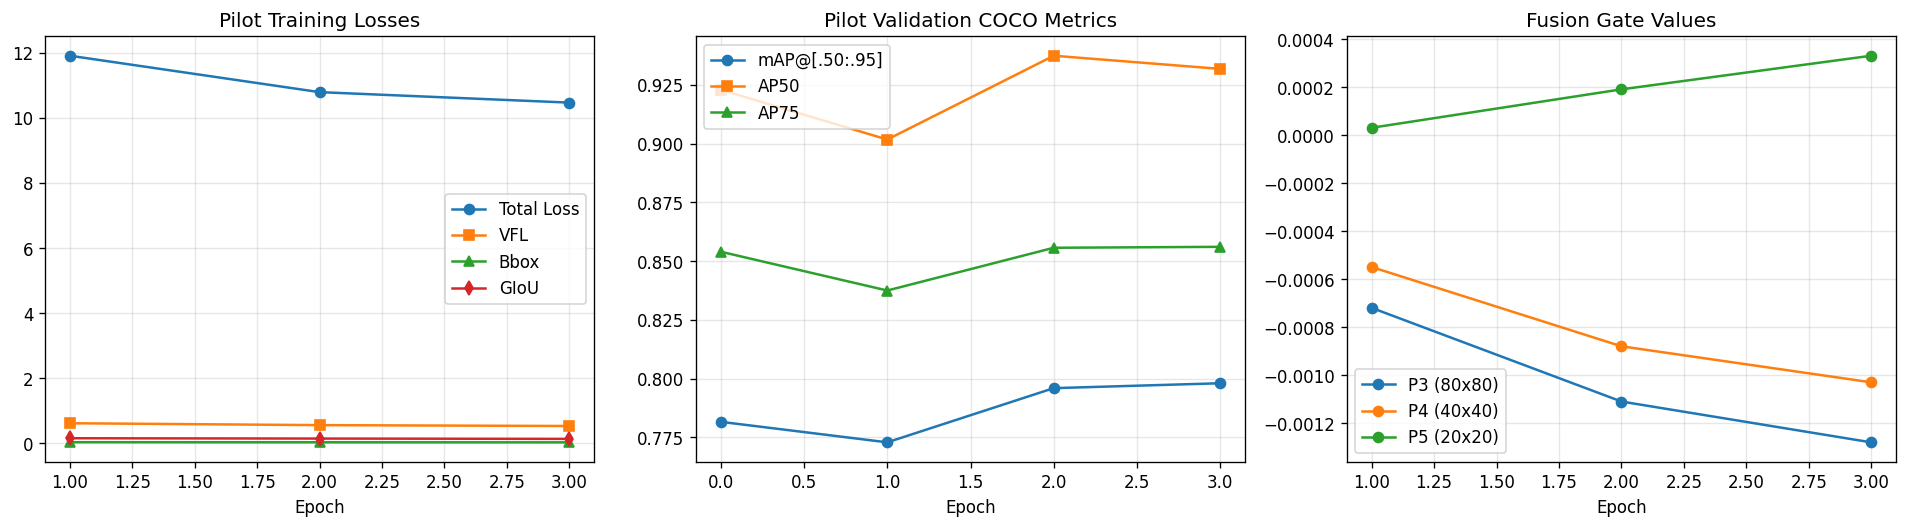

In [7]:
epochs_x = [0] + [h["epoch"] for h in history]
maps_y = [ep0_metrics["mAP"]] + [h["val_mAP"] for h in history]
ap50_y = [ep0_metrics["AP50"]] + [h["val_AP50"] for h in history]
ap75_y = [ep0_metrics["AP75"]] + [h["val_AP75"] for h in history]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot([h["epoch"] for h in history], [h["train_loss"] for h in history], marker="o", label="Total Loss")
axes[0].plot([h["epoch"] for h in history], [h["loss_vfl"] for h in history], marker="s", label="VFL")
axes[0].plot([h["epoch"] for h in history], [h["loss_bbox"] for h in history], marker="^", label="Bbox")
axes[0].plot([h["epoch"] for h in history], [h["loss_giou"] for h in history], marker="d", label="GIoU")
axes[0].set_title("Pilot Training Losses")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_x, maps_y, marker="o", label="mAP@[.50:.95]")
axes[1].plot(epochs_x, ap50_y, marker="s", label="AP50")
axes[1].plot(epochs_x, ap75_y, marker="^", label="AP75")
axes[1].set_title("Pilot Validation COCO Metrics")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

for s_idx, s_name in enumerate(["P3 (80x80)", "P4 (40x40)", "P5 (20x20)"]):
    axes[2].plot([h["epoch"] for h in history], [h["fusion_gates"][s_idx] for h in history], marker="o", label=s_name)
axes[2].set_title("Fusion Gate Values")
axes[2].set_xlabel("Epoch")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

best_row = max(history, key=lambda r: r["val_mAP"])
print(f"\nBest Pilot Val Epoch {best_row['epoch']} | mAP={best_row['val_mAP']:.4f}")
for cls_name, ap in best_row["per_class"].items():
    print(f"  {cls_name:<18}: {ap:.4f}")
